<a href="https://colab.research.google.com/github/b5gye5m/linear-algebra/blob/main/202021005_%EA%B9%80%EB%B3%B4%EA%B2%B8_ex02_transform_tiefighter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 라이브러리 선언

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000  # 그림판 크기
LEN = 100   # 처음 사각형의 크기

### 축 그리기 및 사각형 그리기

In [2]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)  # x-axis line
  ax.axvline(0, color='black', alpha=0.3)  # y-axis line
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')  # 정사각형 모양으로 backboard 그리기

In [3]:
def draw_rectangle(ax, p1, p2, p3, p4):
  my_polygon = Polygon([p1, p2, p3, p4])
  ax.add_patch(my_polygon)

In [4]:
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_rectangle(ax, p1, p2, p3, p4)

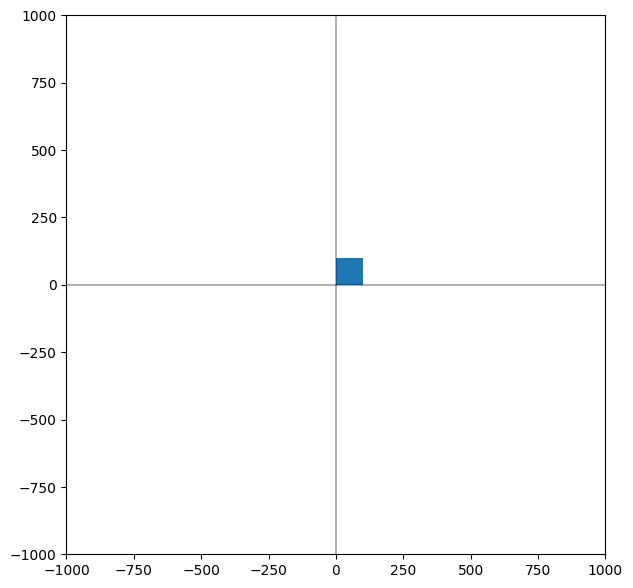

In [5]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기: tie fighter 그리는 주체
draw_object(ax)

plt.show()

### 본론
#### 1. 변환 구현
* translate(p, dx, dy)
* rotate(p, theta)  
* scale(p, sx, sy)  
* shear_x(p, sx)  
* shear_y(p, sy)  
* reflect_x(p)  
* reflect_y(p)   
* reflect_origin(p)
* reflect_xy(p)

In [6]:
# 점 p를 x축 방향으로 dx만큼, y축 방향으로 dy만큼 이동시킨 점 q를 구할 것
# q = T(dx, dy)·p1
def translate(p, dx, dy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 이동 변환 행렬 생성
  m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [7]:
# 점 p를 theta 만큼 회전 시킨 q
# q = R(theta)·p
def rotate(p, theta):
  # 1. 동차좌표계로 (homogeneous coordinate)로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 회전 변환 행렬 생성
  m = np.array([[np.cos(theta), -(np.sin(theta)), 0.0], [np.sin(theta), np.cos(theta), 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [8]:
# 점 p를 x축으로 sx만큼, y축으로 sy만큼 스케일링 한 q
# q = S(sx, sy)·p
def scale(p, sx, sy):
  # 1. 동차좌표계로 (homogeneous coordinate)로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 크기 변환 행렬 생성
  m = np.array([[sx, 0.0, 0.0], [0.0, sy, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [9]:
# 점 p를 x축으로 sx만큼 밀림 변환 한 q
# q = Shx(sx)·p
def shear_x(p, sx):
  # 1. 동차좌표계 (homogeneous coordinate)로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. x축 밀림 변환 행렬 생성
  m = np.array([[1.0, sx, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0],q[1]])
  return q


In [10]:
# 점 p를 y축으로 sy만큼 밀림 변환 한 q
# q = Shy(sy)·p
def shear_y(p, sy):
  # 1. 동차좌표계(homogeneous coordinate)로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. y축 밀림 변환 행렬 생성
  m = np.array([[1.0, 0.0, 0.0], [sy, 1.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0],q[1]])
  return q

In [11]:
# 점 p를 x축 기준으로 반전한 q
# q = Rfx·p
def reflect_x(p):
  # 1. 동차좌표계(homogeneous coordinate)로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. x축 기준 반전 변환 행렬 생성
  m = np.array([[1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0],q[1]])
  return q

In [12]:
# 점 p를 y축 기준으로 반전한 q
# q = Rfy·p
def reflect_y(p):
  # 1. 동차좌표계(homogeneous coordinate)로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. y축 기준 반전 변환 행렬 생성
  m = np.array([[-1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0],q[1]])
  return q

In [13]:
# 점 p를 원점 기준으로 반전한 q
# q = Rfo·p
def reflect_origin(p):
  # 1. 동차좌표계(homogeneous coordinate)로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 원점 기준 반전 변환 행렬 생성
  m = np.array([[-1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [14]:
# 점 p를 y=x 기준으로 반전한 q
# q = Rfxy·p
def reflect_xy(p):
  # 1. 동차좌표계(homogeneous coordinate)로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. y=x 기준 반전 변환 행렬 생성
  m = np.array([[0.0, 1.0, 0.0], [1.0, 0.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

#### 2. 파트 그리기
* draw_cockpit(p1, p2, p3, p4)    # 중앙 조종석
* draw_left_arm(p1, p2, p3, p4)   # 왼쪽 날개축
* draw_left_wing(p1, p2, p3, p4)  # 왼쪽 날개
* draw_right_arm(p1, p2, p3, p4)  # 오른쪽 날개축
* draw_right_wing(p1, p2, p3, p4) # 오른쪽 날개

In [15]:
def draw_cockpit(ax, p1, p2, p3, p4):  # 중앙 조종석
  # 1. 사각형을 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  # q = T(-LEN/2, -LEN/2)p
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)


  # 2. 크기 변환: S(5, 5)
  s = 5
  q1 = scale(q1, s, s)
  q2 = scale(q2, s, s)
  q3 = scale(q3, s, s)
  q4 = scale(q4, s, s)

  # 3. 회전 변환: R(pi/4)
  q1 = rotate(q1, 3.14/4.0)
  q2 = rotate(q2, 3.14/4.0)
  q3 = rotate(q3, 3.14/4.0)
  q4 = rotate(q4, 3.14/4.0)


  # 4. polygon 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

In [16]:
def draw_left_arm(ax, p1, p2, p3, p4): #왼쪽 날개축
  # 위쪽 날개축
  # 1. 사각형을 원점으로 이동변환: T(-LEN/2, -LEN/2)
  # q = T(-LEN/2, -LEN/2)p
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기 변환: S(6, 0.8)
  q1 = scale(q1, 6, 0.8)
  q2 = scale(q2, 6, 0.8)
  q3 = scale(q3, 6, 0.8)
  q4 = scale(q4, 6, 0.8)

  # 3. y축 기울기: shy(-0.2)
  q1 = shear_y(q1, -0.2)
  q2 = shear_y(q2, -0.2)
  q3 = shear_y(q3, -0.2)
  q4 = shear_y(q4, -0.2)

  # 4. 이동: T(500, 50)
  q1 = translate(q1, 500, 50)
  q2 = translate(q2, 500, 50)
  q3 = translate(q3, 500, 50)
  q4 = translate(q4, 500, 50)

  # 5. polygon 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

  # 아랫쪽 날개축
  # 1. 위쪽 날개축을 x축 기준 반전
  r1 = reflect_x(q1)
  r2 = reflect_x(q2)
  r3 = reflect_x(q3)
  r4 = reflect_x(q4)

  # 2. polygon 그리기
  draw_rectangle(ax, r1, r2, r3, r4)

In [17]:
def draw_left_wing(ax, p1, p2, p3, p4): # 왼쪽 날개
  # 1. 원점이동
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4  = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기변환
  q1 = scale(q1, 1, 10)
  q2 = scale(q2, 1, 10)
  q3 = scale(q3, 1, 10)
  q4 = scale(q4, 1, 10)

  # 3. y축 기울임
  q1 = shear_y(q1, -2)
  q2 = shear_y(q2, -2)
  q3 = shear_y(q3, 2)
  q4 = shear_y(q4, 2)

  # 4. 이동
  q1 = translate(q1, 750, 0)
  q2 = translate(q2, 750, 0)
  q3 = translate(q3, 750, 0)
  q4 = translate(q4, 750, 0)

  # 5. polygon 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

In [18]:
def draw_right_arm(ax, p1, p2, p3, p4):
  # 위쪽 날개축
  # 1. 원점 이동
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기 변환
  q1 = scale(q1, 6, 0.8)
  q2 = scale(q2, 6, 0.8)
  q3 = scale(q3, 6, 0.8)
  q4 = scale(q4, 6, 0.8)

  # 3. shy 기울임
  q1 = shear_y(q1, 0.2)
  q2 = shear_y(q2, 0.2)
  q3 = shear_y(q3, 0.2)
  q4 = shear_y(q4, 0.2)

  # 4, 이동
  q1 = translate(q1, -500, 50)
  q2 = translate(q2, -500, 50)
  q3 = translate(q3, -500, 50)
  q4 = translate(q4, -500, 50)

  # 5. polygon 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

  # 아래쪽 날개축
  # 1. 위쪽 날개축을 x축 기준 반전
  r1 = reflect_x(q1)
  r2 = reflect_x(q2)
  r3 = reflect_x(q3)
  r4 = reflect_x(q4)

  # 2. polygon 그리기
  draw_rectangle(ax, r1, r2, r3, r4)

In [19]:
def draw_right_wing(ax, p1, p2, p3, p4):
  # 1. 원점 이동
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기변환
  q1 = scale(q1, 1, 10)
  q2 = scale(q2, 1, 10)
  q3 = scale(q3, 1, 10)
  q4 = scale(q4, 1, 10)

  # 3. shy 기울임
  q1 = shear_y(q1, 2)
  q2 = shear_y(q2, 2)
  q3 = shear_y(q3, -2)
  q4 = shear_y(q4, -2)

  # 4. 이동
  q1 = translate(q1, -750, 0)
  q2 = translate(q2, -750, 0)
  q3 = translate(q3, -750, 0)
  q4 = translate(q4, -750, 0)

  # 5. polygon 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

In [20]:
# 2. tiefigher 그리기
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  # 1. 중앙 조종석 그리기
  draw_cockpit(ax, p1, p2, p3, p4)

  # 2. 왼쪽 날개축 그리기
  draw_left_arm(ax, p1, p2, p3, p4)

  # 3. 왼쪽 날개 그리기
  draw_left_wing(ax, p1, p2, p3, p4) # 왼쪽 날개

  # 4. 오른쪽 날개축 그리기
  draw_right_arm(ax, p1, p2, p3, p4)

  # 5. 오른쪽 날개 그리기
  draw_right_wing(ax, p1, p2, p3, p4)

### 3. main

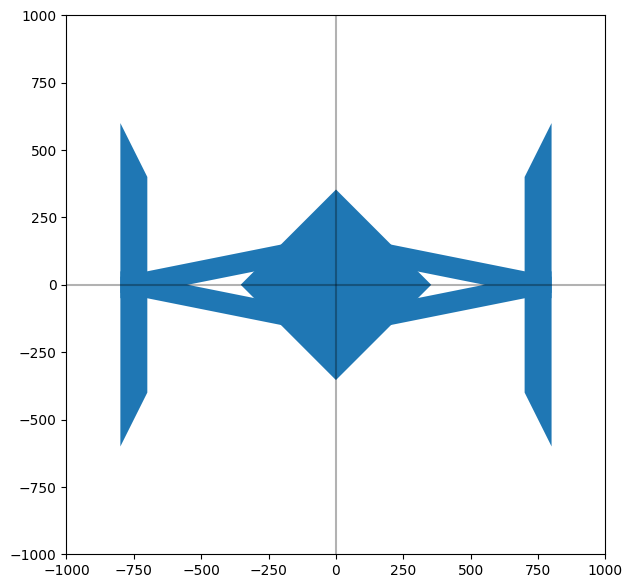

In [21]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()